# Native-volume actual flip angle imaging

The complete acquired 88 by 128 by 32 dual-TR magnitude volumes are reconstructed using independently executed raw AFI inversion. No field or relaxation map from another task is used.

This notebook actively reconstructs the bundled observations. The reproduced upstream result is a method reference, not physical ground truth. No historical paper metric is presented as a measurement from this run.

## Physics and method

The dimensionless signal ratio r=abs(S2/S1) is (1+n cos(a))/(n+cos(a)), where a is actual angle and n=TR2/TR1=5. The inverse is a=arccos((n r-1)/(n-r)); dividing by the nominal 60 degree angle gives relative transmit field B. This is the fully spoiled short-TR approximation, not an exact finite-T1 inverse.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
from matplotlib import pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
if not (ROOT/'src').exists(): raise RuntimeError('Execute from task or notebooks directory')
sys.path.insert(0,str(ROOT))
from src.solvers import reconstruct
from src.visualization import comparison,metrics
started=time.perf_counter()
fresh=reconstruct(ROOT/'data/raw_data.npz')
runtime=time.perf_counter()-started
reference=dict(np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False))
print('Fresh local reconstruction CPU wall seconds:',runtime)
for key,value in fresh.items(): print(key,value.shape,value.dtype,metrics(value,reference[key]))
print('Kernel:',sys.executable,'NumPy:',np.__version__)

Fresh local reconstruction CPU wall seconds: 0.019038799917325377
reconstruction (1, 88, 128, 32) float64 (1.0000000000000002, 0.0)
Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


In [2]:
import hashlib
ledger=json.loads((ROOT/'notebooks/reference_outputs/fresh_metrics.json').read_text(encoding='utf-8'))
assert ledger['observation_sha256']==hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print('Measurement ledger:',ledger['kind'])
for key in fresh:
 n,e=metrics(fresh[key],reference[key])
 assert abs(e-ledger['judge_report']['metrics'][key+'_nrmse'])<1e-12
print('Fresh measurement ledger matches this active reconstruction.')

Measurement ledger: fresh cleaned-code measurement, not historical report
Fresh measurement ledger matches this active reconstruction.


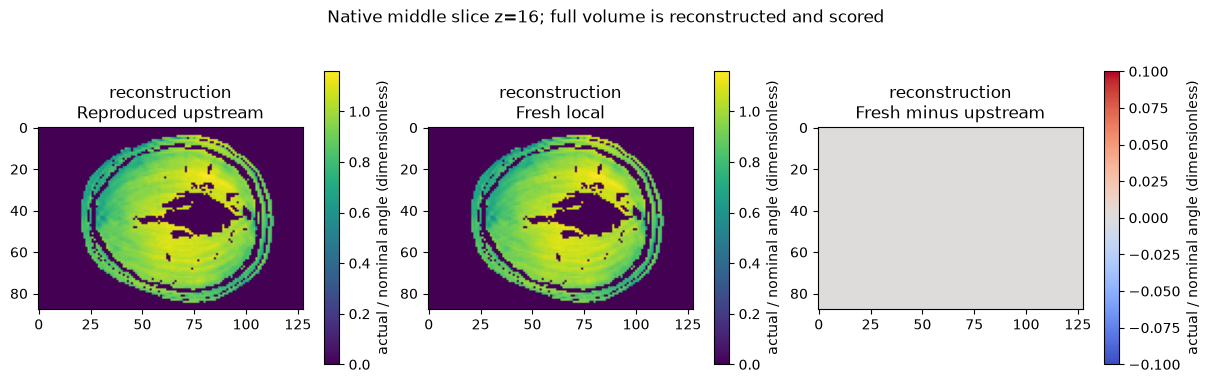

In [3]:
fig=comparison(fresh,reference)
fig.suptitle('Native middle slice z=16; full volume is reconstructed and scored')
plt.show()

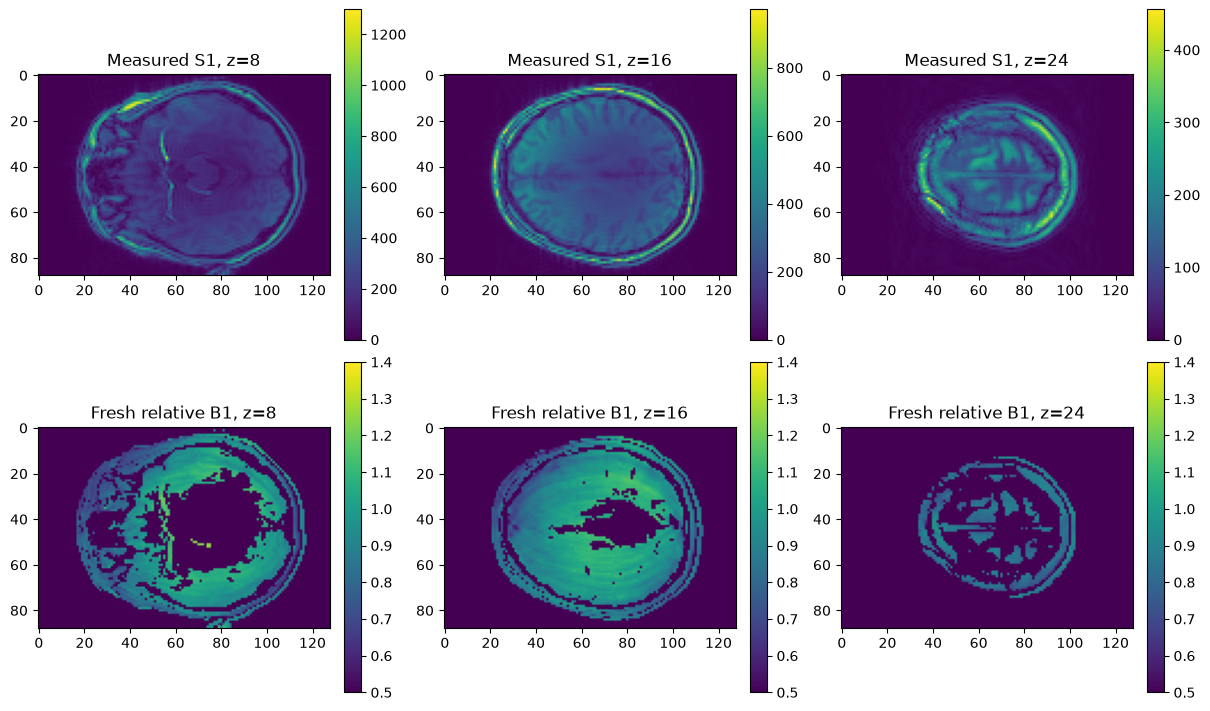

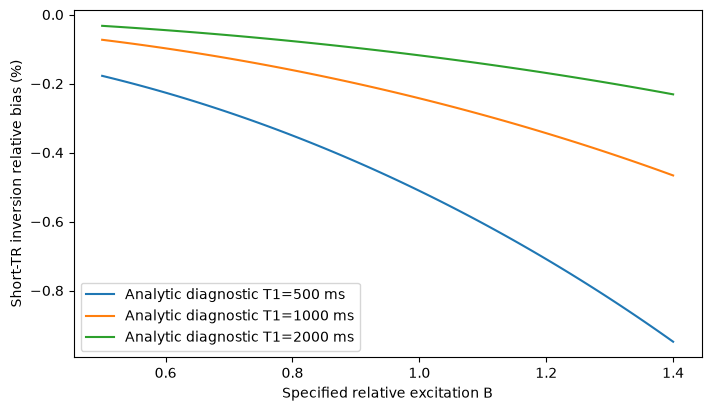

Finite-TR bias is a model approximation limitation, not an error against measured truth.


In [4]:
from src.preprocessing import load_data
from src.physics_model import exact_steady_state,invert_afi
signal,mask=load_data(ROOT/'data/raw_data.npz')
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained')
for column,z in enumerate([8,16,24]):
 im=axes[0,column].imshow(signal[:,:,z,0]);axes[0,column].set_title('Measured S1, z='+str(z));fig.colorbar(im,ax=axes[0,column])
 im=axes[1,column].imshow(fresh['reconstruction'][0,:,:,z],vmin=.5,vmax=1.4);axes[1,column].set_title('Fresh relative B1, z='+str(z));fig.colorbar(im,ax=axes[1,column])
plt.show()
# Independent analytic diagnostic: these T1 values are not benchmark truth.
b=np.linspace(.5,1.4,100)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for t1 in [500.,1000.,2000.]:
 exact=exact_steady_state(b,t1)
 inferred=invert_afi(exact)
 ax.plot(b,100*(inferred-b)/b,label='Analytic diagnostic T1='+str(int(t1))+' ms')
ax.set(xlabel='Specified relative excitation B',ylabel='Short-TR inversion relative bias (%)')
ax.legend();plt.show()
print('Finite-TR bias is a model approximation limitation, not an error against measured truth.')


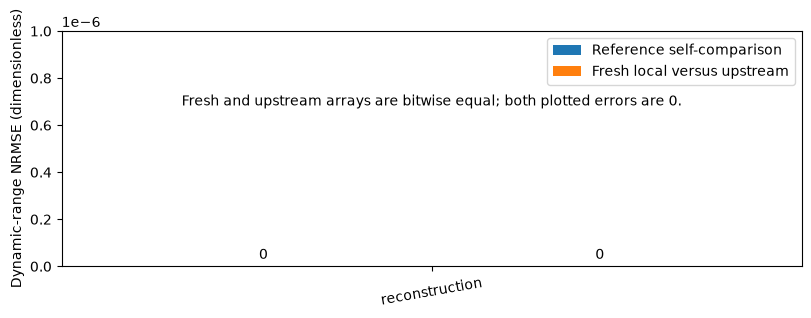

{
  "reconstruction": {
    "NCC": 1.0000000000000002,
    "dynamic_range_NRMSE": 0.0
  }
}


In [5]:
labels=list(fresh)
errors=[metrics(fresh[k],reference[k])[1] for k in labels]
fig,ax=plt.subplots(figsize=(8,3),layout='constrained')
x=np.arange(len(labels))
reference_bars=ax.bar(x-.18,[metrics(reference[k],reference[k])[1] for k in labels],.36,label='Reference self-comparison')
fresh_bars=ax.bar(x+.18,errors,.36,label='Fresh local versus upstream')
ax.margins(y=.18)
ax.bar_label(reference_bars,fmt='%.3g',padding=3)
ax.bar_label(fresh_bars,fmt='%.3g',padding=3)
ax.set_xticks(x,labels,rotation=10);ax.set_ylabel('Dynamic-range NRMSE (dimensionless)');ax.legend()
if all(error==0 for error in errors):
 ax.set_ylim(0,1e-6)
 ax.text(.5,.7,'Fresh and upstream arrays are bitwise equal; both plotted errors are 0.',ha='center',va='center',transform=ax.transAxes,wrap=True)
plt.show()
print(json.dumps({k:dict(zip(['NCC','dynamic_range_NRMSE'],metrics(fresh[k],reference[k]))) for k in labels},indent=2))

## Interpretation

The result is a relative excitation field map. Native volume coverage is preserved, and low-signal/spurious support is explicitly fixed from observations. Finite-TR approximation bias is examined independently and is not hidden by reference agreement. Numerical reference agreement establishes extraction fidelity; it does not establish biological or clinical accuracy.